In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix, classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

df = pd.read_csv("data.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:

# Remove unnecessary columns
df_clean = df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Convert diagnosis to numerical values
# Malignant = 1, Benign = 0
df_clean["diagnosis"] = df_clean["diagnosis"].map({
    "M": 1,
    "B": 0
})

# Separate features and target
X = df_clean.drop("diagnosis", axis=1)
y = df_clean["diagnosis"]

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X.shape[1])


Training samples: 455
Testing samples: 114
Number of features: 30


In [4]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

# Create Decision Tree classifier
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

# Predict test data
y_pred = dt_model.predict(X_test)

# Display classification results
print("DECISION TREE CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))


DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign       0.89      0.97      0.93        72
   Malignant       0.94      0.79      0.86        42

    accuracy                           0.90       114
   macro avg       0.91      0.88      0.89       114
weighted avg       0.91      0.90      0.90       114

Accuracy: 0.9035
Precision: 0.9429
Recall: 0.7857
F1 Score: 0.8571


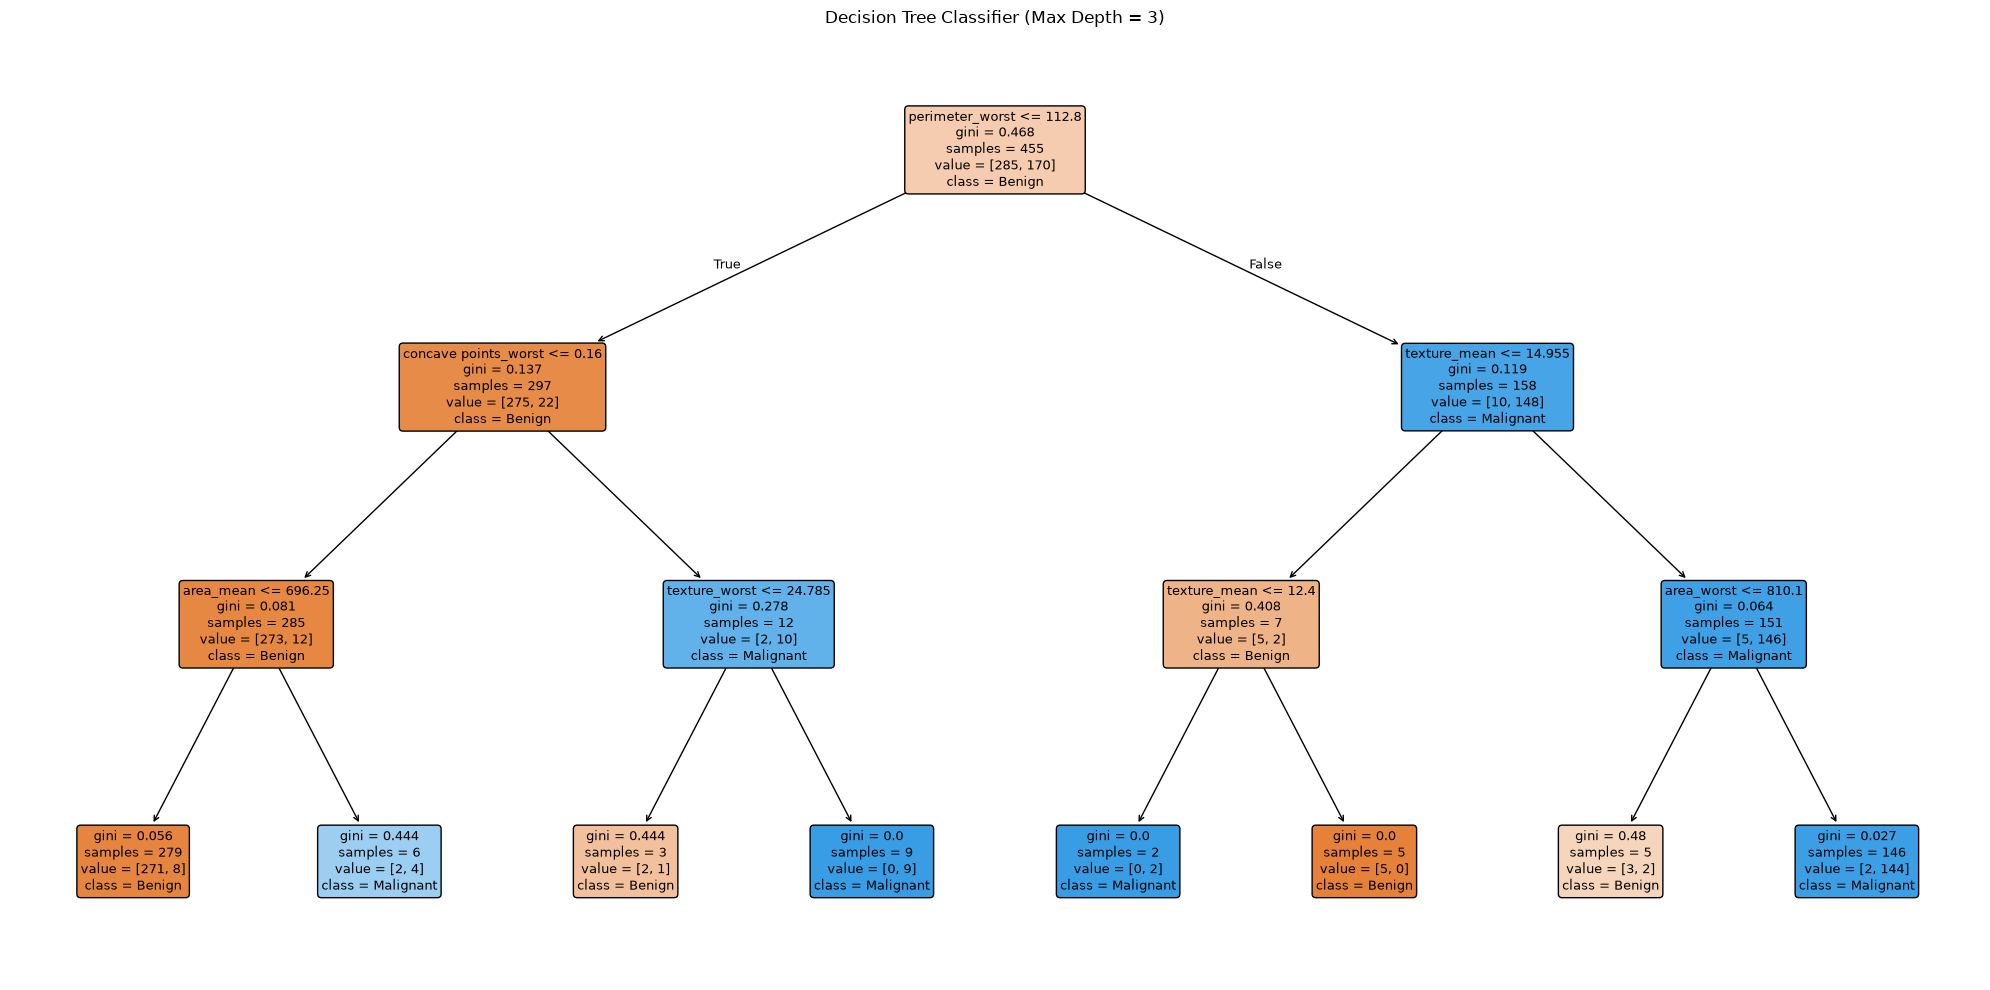

In [5]:

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["Benign", "Malignant"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classifier (Max Depth = 3)")
plt.tight_layout()
plt.show()


In [6]:

from sklearn.model_selection import StratifiedKFold, cross_val_score

depth_values = range(1, 16)
depth_results = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for depth in depth_values:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracy = model.score(X_train, y_train)

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    depth_results.append({
        "Max Depth": depth,
        "Training Accuracy": train_accuracy,
        "Mean CV Accuracy": cv_scores.mean()
    })

depth_results_df = pd.DataFrame(depth_results)

print("EFFECT OF TREE DEPTH ON CLASSIFICATION")
display(depth_results_df.round(4))

best_depth = int(
    depth_results_df.loc[
        depth_results_df["Mean CV Accuracy"].idxmax(),
        "Max Depth"
    ]
)

print("\nBest Tree Depth:", best_depth)


EFFECT OF TREE DEPTH ON CLASSIFICATION


,Max Depth,Training Accuracy,Mean CV Accuracy
0,1,0.9297,0.9011
1,2,0.9538,0.9209
2,3,0.9670,0.9209
3,4,0.9824,0.9209
4,5,0.9868,0.9077
5,6,0.9934,0.9209
6,7,0.9956,0.9231
7,8,1.0000,0.9231
8,9,1.0000,0.9231
9,10,1.0000,0.9231



Best Tree Depth: 7


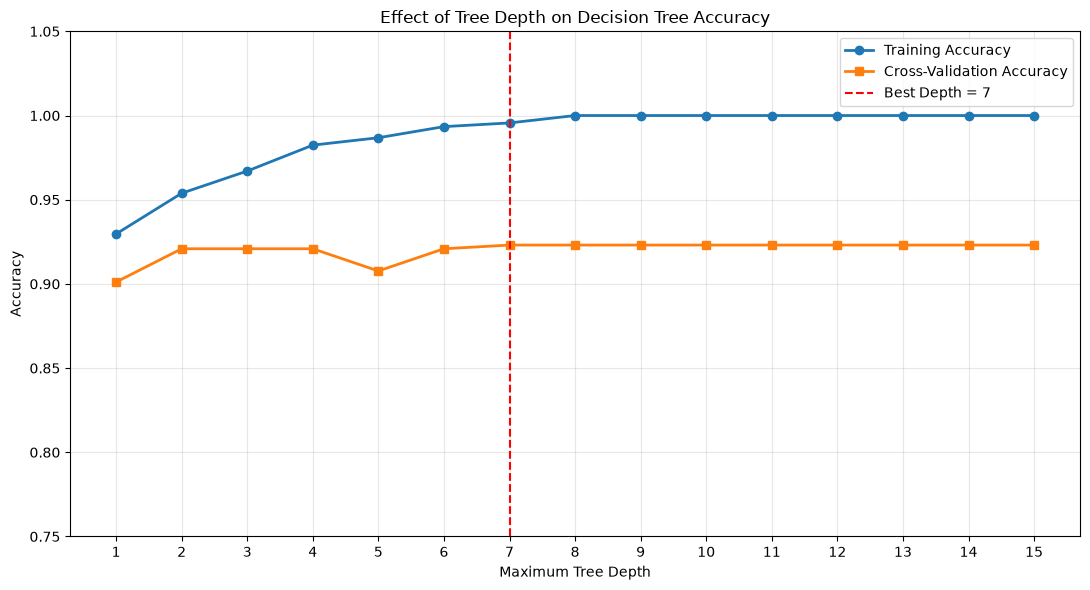

In [7]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.plot(
    depth_results_df["Max Depth"],
    depth_results_df["Training Accuracy"],
    marker="o",
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    depth_results_df["Max Depth"],
    depth_results_df["Mean CV Accuracy"],
    marker="s",
    linewidth=2,
    label="Cross-Validation Accuracy"
)

plt.axvline(
    x=best_depth,
    color="red",
    linestyle="--",
    label=f"Best Depth = {best_depth}"
)

plt.title("Effect of Tree Depth on Decision Tree Accuracy")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.xticks(list(depth_values))
plt.ylim(0.75, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [8]:

# Train the optimized Decision Tree

best_dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=best_depth,
    random_state=42
)

best_dt.fit(X_train, y_train)

# Predict on the test dataset
best_pred = best_dt.predict(X_test)

# Display classification results
print("BEST DECISION TREE CLASSIFICATION RESULTS")

print(classification_report(
    y_test,
    best_pred,
    target_names=["Benign", "Malignant"]
))

print("Accuracy:", round(accuracy_score(y_test, best_pred), 4))
print("Precision:", round(precision_score(y_test, best_pred), 4))
print("Recall:", round(recall_score(y_test, best_pred), 4))
print("F1 Score:", round(f1_score(y_test, best_pred), 4))


BEST DECISION TREE CLASSIFICATION RESULTS
              precision    recall  f1-score   support

      Benign       0.93      0.97      0.95        72
   Malignant       0.95      0.88      0.91        42

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114

Accuracy: 0.9386
Precision: 0.9487
Recall: 0.881
F1 Score: 0.9136


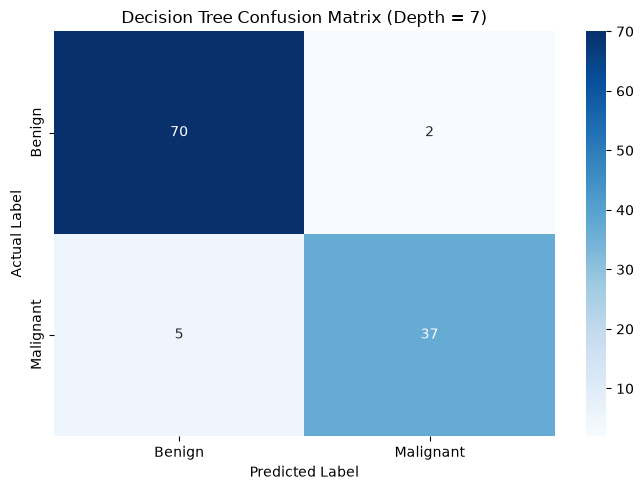

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, best_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("Decision Tree Confusion Matrix (Depth = 7)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


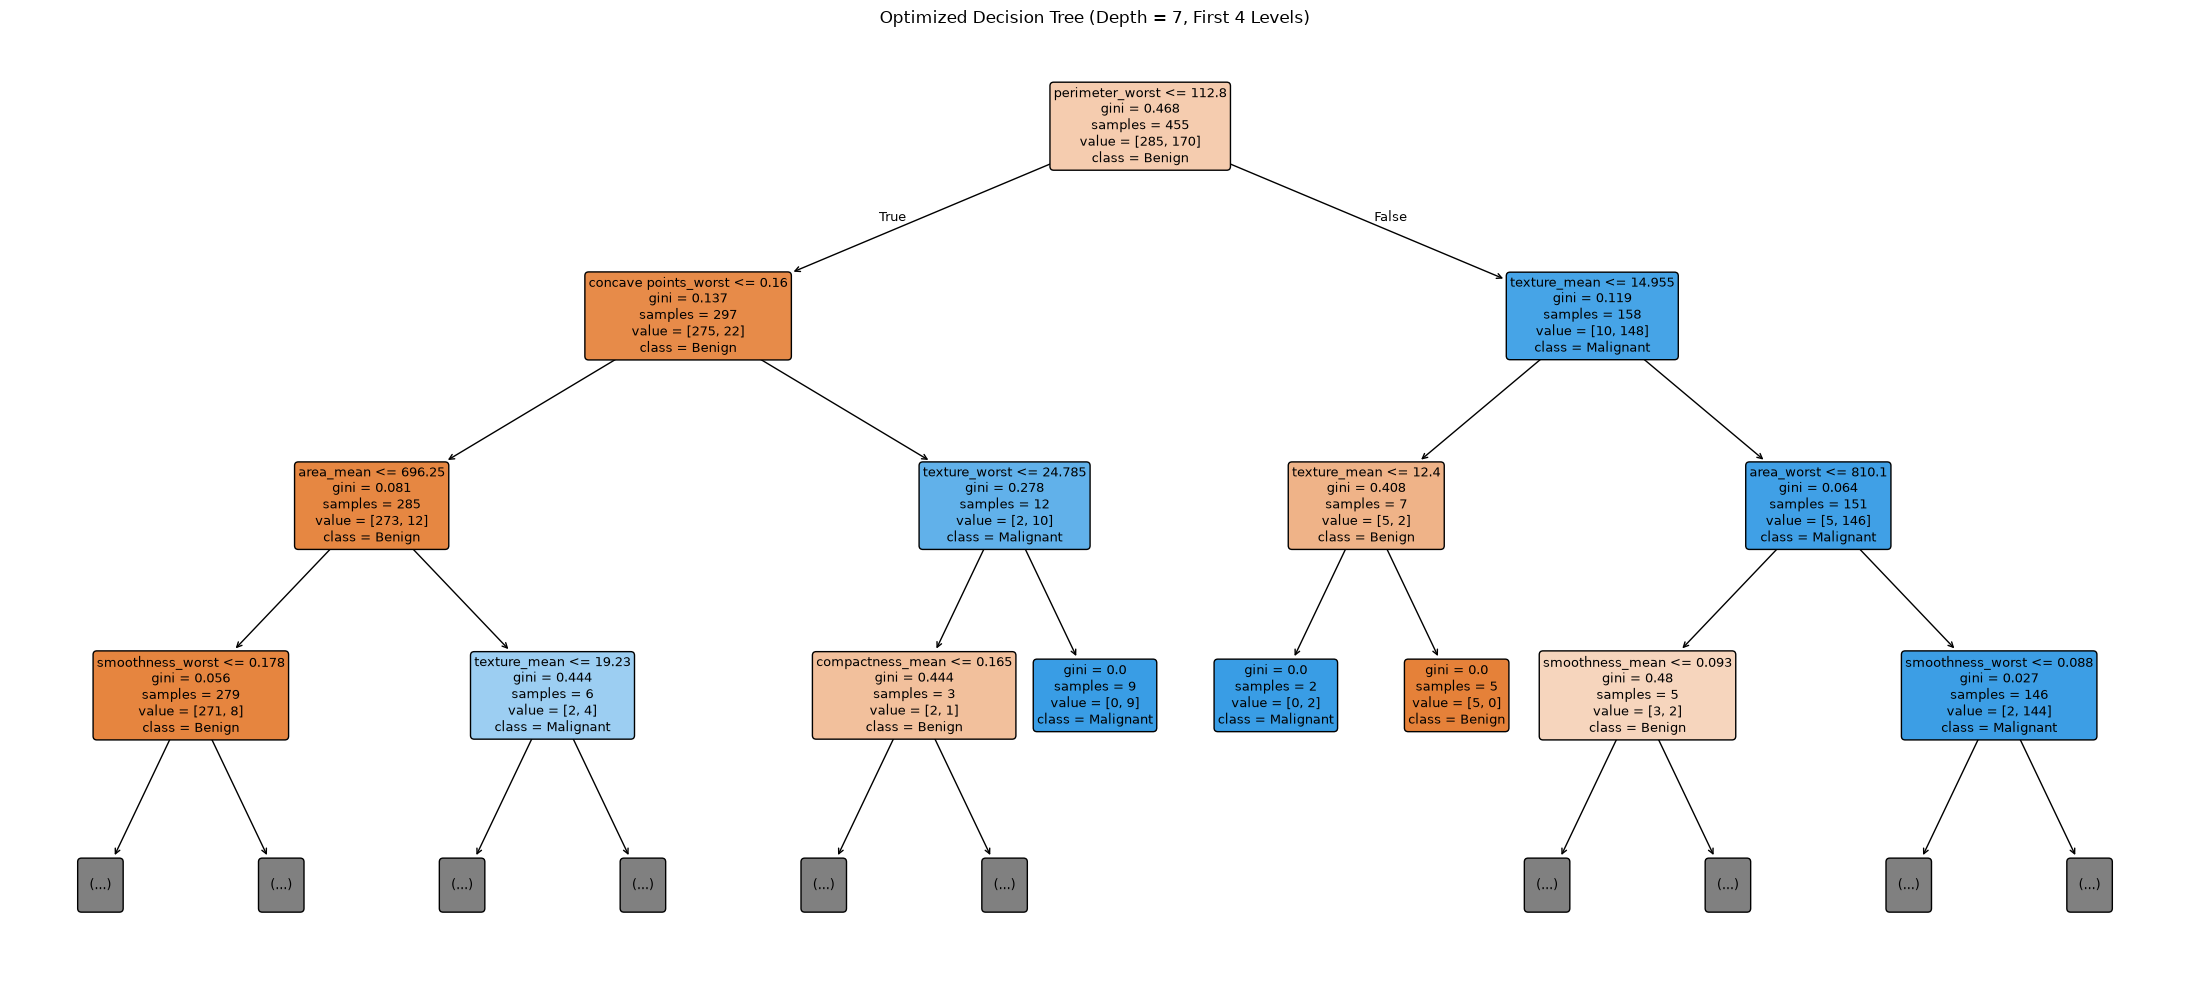

In [10]:

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 10))

plot_tree(
    best_dt,
    feature_names=X.columns,
    class_names=["Benign", "Malignant"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Optimized Decision Tree (Depth = 7, First 4 Levels)")
plt.tight_layout()
plt.show()


In [11]:

print("=" * 45)
print("EXPERIMENT 6: DECISION TREE FINAL RESULT")
print("=" * 45)

print("Best Tree Depth:", best_depth)
print("Accuracy:", round(accuracy_score(y_test, best_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, best_pred), 4))
print("Recall:", round(recall_score(y_test, best_pred), 4))
print("F1 Score:", round(f1_score(y_test, best_pred), 4))

print("\nExperiment Completed Successfully!")


EXPERIMENT 6: DECISION TREE FINAL RESULT
Best Tree Depth: 7
Accuracy: 93.86 %
Precision: 0.9487
Recall: 0.881
F1 Score: 0.9136

Experiment Completed Successfully!
